# Battery EMS - House with one battery

## Introduction to Dynamic Energy Management Systems (EMS) for Battery Optimization

In modern power systems, energy storage plays a crucial role in balancing supply and demand, integrating renewable energy, and optimizing energy costs. An Energy Management System (EMS) is responsible for making real-time or scheduled decisions on how to operate an energy storage system (ESS), such as a battery, in response to grid conditions, electricity prices, and user energy demands.

Dynamic EMS refers to an EMS that adapts its control decisions over time, based on real-time data, forecasts, and optimization techniques. Instead of following predefined static rules, a dynamic EMS employs mathematical optimization to determine the best charging and discharging strategy for the battery at each decision interval.

### Optimization in Battery EMS

From an optimization perspective, managing a battery in a dynamic EMS involves solving a multi-period decision problem where the system must determine:

* When to charge the battery (and how much energy to store)
* When to discharge the battery (and how much energy to release)
* When to buy or sell energy from the grid (considering electricity prices and grid constraints)
* How to prioritize self-consumption vs. grid interaction (e.g., using excess solar generation vs. performing energy arbitrage)

This decision-making process must satisfy several operational constraints, including:

* Battery dynamics: The state-of-charge (SOC) must be updated correctly based on energy flows and efficiency losses.
* Power limits: Charging and discharging rates must not exceed the battery’s capacity.
* Grid constraints: The power drawn from the grid should not exceed a contracted limit.
* Economic objectives: The EMS should minimize total energy costs (or maximize profits from grid interactions).

### Dynamic Optimization Formulation

Mathematically, this problem is formulated as a Mixed-Integer Linear Program (MILP), where:

* Decision variables represent battery charge/discharge actions, grid interactions, and energy flow.
* Objective function aims to minimize the total cost of energy over a planning horizon.
* Constraints enforce battery and grid limitations while ensuring energy balance.

### Why is Dynamic EMS Important?

Unlike static rule-based approaches, a dynamic EMS continuously adapts to changing energy conditions. This is particularly valuable for:

* Smart grids: Integrating renewable energy sources with fluctuating availability (e.g., solar, wind).
* Demand-side management: Reducing peak grid consumption and improving self-consumption.
* Economic optimization: Taking advantage of variable electricity prices through energy arbitrage.
* Grid constraints & regulations: Ensuring compliance with contractual power limits.

By leveraging optimization techniques, dynamic EMS solutions enable more efficient, cost-effective, and flexible battery management strategies. This notebook presents an optimization-based EMS that determines optimal battery operation over a 15-minute resolution using HiGHS, a high-performance linear programming solver.

## Formulation and Solution

The solver adopted here is HiGHS. It is an open-source, high-performance optimization solver designed to handle linear programming (LP), 
mixed-integer programming (MIP), and quadratic programming (QP) problems efficiently. It provides state-of-the-art algorithms for 
solving large-scale optimization problems and is widely used in academia and industry.

Official Website: https://highs.dev/
GitHub Repository: https://github.com/ERGO-Code/HiGHS
Academic Paper: Hall, J. A. J., Huangfu, Q., & Miltenberger, M. (2020). HiGHS - A high-performance linear optimization solver. DOI: 10.48550/arXiv.2002.04030

In [1]:
import numpy as np
import highspy
import random

h = highspy.Highs()

### Parameters

In [2]:
T = 96  # 15-minute resolution: 24h * 4 = 96 periods
time_periods = list(range(T)) # Time periods

tariff_type = 'bi'
can_sell_injection = False

if tariff_type == 'tri':
    # Define the number of periods for each tariff block
    periods = {
        "P3_Vazio_1": 32,  # 00:00–08:00
        "P2_Cheias_1": 10, # 08:00–10:30
        "P1_Ponta": 10,    # 10:30–13:00
        "P2_Cheias_2": 26, # 13:00–19:30
        "P1_Ponta_2": 6,   # 19:30–21:00
        "P2_Cheias_3": 4,  # 21:00–22:00
        "P3_Vazio_2": 8    # 22:00–24:00
    }
    
    # Tariff assignments (consumption prices in €/kWh)
    tariff_consumption = {
        "P1": 0.30,  # Ponta
        "P2": 0.20,  # Cheias
        "P3": 0.10   # Vazio
    }
    
    # Tariff assignments for injection prices (€/kWh)
    tariff_injection = {
        "P1": 0.05,
        "P2": 0.06,
        "P3": 0.07
    }
    
    # Build the consumption price array following the schedule:
    # 00:00–08:00: P3, 08:00–10:30: P2, 10:30–13:00: P1, 13:00–19:30: P2,
    # 19:30–21:00: P1, 21:00–22:00: P2, 22:00–24:00: P3.
    price_consumption = []
    price_consumption += [tariff_consumption["P3"]] * periods["P3_Vazio_1"]
    price_consumption += [tariff_consumption["P2"]] * periods["P2_Cheias_1"]
    price_consumption += [tariff_consumption["P1"]] * periods["P1_Ponta"]
    price_consumption += [tariff_consumption["P2"]] * periods["P2_Cheias_2"]
    price_consumption += [tariff_consumption["P1"]] * periods["P1_Ponta_2"]
    price_consumption += [tariff_consumption["P2"]] * periods["P2_Cheias_3"]
    price_consumption += [tariff_consumption["P3"]] * periods["P3_Vazio_2"]
    
    # Build the injection price array following the schedule:
    # For injection, we use the names given in the schedule.
    if can_sell_injection:
        price_injection = []
        price_injection += [tariff_injection["P3"]] * periods["P3_Vazio_1"]
        price_injection += [tariff_injection["P2"]] * periods["P2_Cheias_1"]
        price_injection += [tariff_injection["P1"]] * periods["P1_Ponta"]
        price_injection += [tariff_injection["P2"]] * periods["P2_Cheias_2"]
        price_injection += [tariff_injection["P1"]] * periods["P1_Ponta_2"]
        price_injection += [tariff_injection["P2"]] * periods["P2_Cheias_3"]
        price_injection += [tariff_injection["P3"]] * periods["P3_Vazio_2"]
    else:
        price_injection = [-0.01] * T

elif tariff_type == 'bi':

    # Tariff values (€/kWh)
    P1_Fora_Vazio = 0.30  # P1 tariff: Fora Vazio
    P2_Vazio = 0.20       # P2 tariff: Vazio
    
    # Build the consumption price array for a 24-hour period at 15-min resolution (96 periods):
    # 00:00 - 08:00: 32 periods at P2 Vazio
    # 08:00 - 22:00: 56 periods at P1 Fora Vazio
    # 22:00 - 24:00: 8 periods at P2 Vazio
    price_consumption = []
    price_consumption += [P2_Vazio] * 32  # 00:00–08:00
    price_consumption += [P1_Fora_Vazio] * 56  # 08:00–22:00
    price_consumption += [P2_Vazio] * 8   # 22:00–24:00

    if can_sell_injection:
        price_injection = []
        price_injection += [P2_Vazio/5] * 32  # 00:00–08:00
        price_injection += [P1_Fora_Vazio/5] * 56  # 08:00–22:00
        price_injection += [P2_Vazio/5] * 8   # 22:00–24:00
    else:
        price_injection = [-0.01] * T


else:

    print("Tariff type not recognized")


# Forecasted house load and solar production (kWh per period)
# Construct a realistic forecast load profile for a weekday for a family of two
# with a fully electric house (including two baths) at 15-min resolution (96 periods).
forecast_load = []
forecast_load += [random.uniform(0.06, 0.08) for _ in range(24)]  # Nighttime: low base load
forecast_load += [random.uniform(0.06, 0.1) for _ in range(18)]   # Morning: peak load (breakfast, morning routines)
# forecast_load += [random.uniform(0.2, 0.4) for _ in range(26)]  # Daytime: lower load while at work
forecast_load += [random.uniform(0.06, 0.09) for _ in range(26)]  # Daytime: lower load while at work
forecast_load += [random.uniform(0.12, 0.24) for _ in range(16)]  # Evening: high load (dinner, cooking, baths)
forecast_load += [random.uniform(0.06, 0.08) for _ in range(12)]  # Late evening: moderate load

# Parameters for the solar production cubic
A = 0.06  # Peak solar production (kWh per period) at noon (t=48)

def solar_production(t, A):
    # Define active period: from period 36 (09:00) to period 72 (18:00)
    if t < 36 or t > 72:
        return 0.0
    else:
        # Cubic function: f(t) = a*t^3 + b*t^2 + c*t + d
        # Coefficients chosen such that:
        # f(36)=0, f(48)=A, f(72)=0, and f'(36)=0 for smooth sunrise.
        a = -A / 3456.0
        b = A / 24.0
        c = -1.875 * A
        d = 27 * A
        return a * t**3 + b * t**2 + c * t + d

# Build the forecast_solar array using the cubic function over the day
forecast_solar = [solar_production(t, A) for t in range(T)]


# Battery/system parameters
SOC_min, SOC_max = 5, 95    # Battery SOC bounds (%)
SOC_init = 80               # Initial SOC (%)
SOC_min_final = 80           # Min Final SOC (%)
# SOC_min_final = 0           # Min Final SOC (%)
battery_capacity = 5         # Battery capacity (kWh)
eta = 0.9                    # Charging efficiency
inv_eta = 1.0 / eta          # Inverse of charging efficiency
P_charge = 4                 # Charging power (kW)
P_discharge = 4              # Discharging power (kW)
delta_t = 0.25               # 15 minutes in hours
lambda_penalty = list([0 for t in range(T)])
arbitrage_penalty = list(reversed([1.0 + t*0.001 for t in range(T)]))
arbitrage_switch_penalty = 1.0

# Contracted power (kW) for grid import
P_contract = 10              # Maximum power that can be drawn from the grid

### Variables

In [3]:
print("Variables...")

# 1. Mode variable: m[t] = 1 means arbitrage mode; m[t] = 0 means self consumption.
m = h.addVariables(time_periods,
                   obj=arbitrage_penalty,
                   lower=[0]*T,
                   upper=[1]*T,
                   name=["m_%d" % t for t in time_periods])
for t in time_periods:
    h.setInteger(m[t])

# 2. Binary variable for settlement: settle[t] = 1 means import is active, 0 means export is active.
settle_grid = h.addVariables(time_periods, obj=[0]*T, lower=[0]*T, upper=[1]*T, name=["settle_grid_%d" % t for t in time_periods])
settle_battery = h.addVariables(time_periods, obj=[0]*T, lower=[0]*T, upper=[1]*T, name=["settle_battery_%d" % t for t in time_periods])
for t in time_periods:
    h.setInteger(settle_grid[t])
    h.setInteger(settle_battery[t])

# 3. Binary variable for charging power (dimensionless) in arbitrage mode.
x = h.addVariables(time_periods,
                   obj=[price_consumption[t] for t in time_periods],
                   lower=[0]*T,
                   upper=[1]*T,
                   name=["x_%d" % t for t in time_periods])
for t in time_periods:
    h.setInteger(x[t])

# 4. Binary variable for discharging power (dimensionless) in arbitrage mode.
z = h.addVariables(time_periods,
                   obj=[0]*T,
                   lower=[0]*T,
                   upper=[1]*T,
                   name=["z_%d" % t for t in time_periods])
for t in time_periods:
    h.setInteger(z[t])

# 5. Switching indicator for x: y[t], cost = switching penalty (set y_0 = 0).
y_m = h.addVariables(time_periods,
                   obj=[arbitrage_switch_penalty for t in time_periods],
                   lower=[0]*T,
                   upper=[1]*T,
                   name=["y_m_%d" % t for t in time_periods])
y_x = h.addVariables(time_periods,
                   obj=[lambda_penalty[t] for t in time_periods],
                   lower=[0]*T,
                   upper=[1]*T,
                   name=["y_x_%d" % t for t in time_periods])
y_z = h.addVariables(time_periods,
                   obj=[lambda_penalty[t] for t in time_periods],
                   lower=[0]*T,
                   upper=[1]*T,
                   name=["y_z_%d" % t for t in time_periods])
for t in time_periods:
   h.setInteger(y_x[t])
   h.setInteger(y_z[t])
   h.setInteger(y_m[t])


# 6. Continuous charging power (dimensionless) for self consumption.
u = h.addVariables(time_periods,
                   obj=[0]*T,
                   lower=[0]*T,
                   upper=[1]*T,
                   name=["u_%d" % t for t in time_periods])

# 7. Continuous discharging power (dimensionless) for self consumption.
v = h.addVariables(time_periods,
                   obj=[0]*T,
                   lower=[0]*T,
                   upper=[1]*T,
                   name=["v_%d" % t for t in time_periods])

# 8. Battery SOC (state-of-charge), continuous.
soc = h.addVariables(time_periods,
                     obj=[0]*T,
                     lower=[SOC_min]*T,
                     upper=[SOC_max]*T,
                     name=["SOC_%d" % t for t in time_periods])

# 9. Battery charge (dimensionless), continuous.
charge = h.addVariables(time_periods,
                     obj=[0]*T,
                     lower=[0]*T,
                     upper=[delta_t * eta * P_charge]*T,  
                     name=["charge_%d" % t for t in time_periods])

# 10. Battery discharge (dimensionless), continuous.
discharge = h.addVariables(time_periods,
                     obj=[0]*T,
                     lower=[0]*T,
                     upper=[delta_t * inv_eta * P_discharge]*T,  
                     name=["discharge_%d" % t for t in time_periods])

# 11. Energy imported from the grid (kWh); cost = consumption price.
grid_in = h.addVariables(time_periods,
                         obj=[price_consumption[t] for t in time_periods],
                         name=["grid_in_%d" % t for t in time_periods])

# 12. Energy injected into the grid (kWh); cost = -injection price.
grid_out = h.addVariables(time_periods,
                          obj=[-price_injection[t] for t in time_periods],
                          name=["grid_out_%d" % t for t in time_periods])

# 13. Available battery capacity
available_charge = h.addVariables(time_periods,
     obj=[0]*T,
     lower=[0]*T,
     upper=[battery_capacity]*T,  
     name=["available_charge_%d" % t for t in time_periods]
)
available_discharge = h.addVariables(time_periods,
     obj=[0]*T,
     lower=[0]*T,
     upper=[battery_capacity]*T,  
     name=["available_discharge_%d" % t for t in time_periods]
)

print("...done")

Variables...
...done


## Constraints

In [4]:
print("Constraints...")

# Testing

# Fixed mode is self-consumption
# h.addConstrs(
#     (m[t] == 0 for t in time_periods for t in time_periods if t>30),
#     name=["Force_arbitrage%d" % t for t in time_periods if t>30]
# )

# h.addConstrs(
#     (m[t] == 0 for t in time_periods if t == 0),
#     name=["Force_arbitrage%d" % t for t in time_periods if t == 0]
# )

# Fixed mode is arbitrage
# h.addConstrs(
#     (m[t] == 1 for t in time_periods),
#     name=["Force_arbitrage%d" % t for t in time_periods]
#)

# Boundary conditions:
h.addConstr(x[0] == x[1], name="x_initial")
h.addConstr(z[0] == z[1], name="z_initial")
h.addConstr(u[0] == u[1], name="u_initial")
h.addConstr(v[0] == v[1], name="v_initial")
h.addConstr(m[0] == m[1], name="m_initial")
h.addConstr(x[time_periods[-1]] == x[time_periods[-2]], name="x_final")
h.addConstr(z[time_periods[-1]] == z[time_periods[-2]], name="z_final")
h.addConstr(u[time_periods[-1]] == u[time_periods[-2]], name="u_final")
h.addConstr(v[time_periods[-1]] == v[time_periods[-2]], name="v_final")
h.addConstr(m[time_periods[-1]] == m[time_periods[-2]], name="m_final")


# 1. Battery charge energy
h.addConstrs(
    (charge[t] == delta_t * eta * P_charge * (x[t] + u[t])
     for t in time_periods),
    name=["Charge_calc_%d" % t for t in time_periods]
)
h.addConstrs(
    ( 100.0 / battery_capacity * available_charge[t] == SOC_max - soc[t]
     for t in time_periods),
    name=["Available_Charge_calc_%d" % t for t in time_periods]
)

# 2. Battery discharge energy
h.addConstrs(
    (discharge[t] == delta_t * P_discharge / eta * (z[t] + v[t])
     for t in time_periods),
    name=["Discharge_calc_%d" % t for t in time_periods]
)
h.addConstrs(
    ( 100.0 / battery_capacity * available_discharge[t] == soc[t] - SOC_min
     for t in time_periods),
    name=["Available_Discharge_calc_%d" % t for t in time_periods]
)

# 3. Energy balance in the battery
h.addConstrs(
    (soc[t] == soc[t-1] + 100 / battery_capacity * (charge[t-1] - discharge[t-1])
     for t in time_periods if t > 0),
    name=["SOC_dyn_%d" % t for t in time_periods if t > 0]
)

# 4. SOC bounds
h.addConstrs((soc[t] >= SOC_min for t in time_periods),
             name=["SOC_min_%d" % t for t in time_periods])
h.addConstrs((soc[t] <= SOC_max for t in time_periods),
             name=["SOC_max_%d" % t for t in time_periods])

# 5. SOC at t=0
h.addConstr(soc[0] == SOC_init, name="SOC_initial")

# 6. (optional) SOC at final t
if SOC_min_final > SOC_min:
    h.addConstrs((soc[time_periods[-1]] >= SOC_min_final,), name=["SOC_min_final"])

# 7. Energy balance at house
h.addConstrs(
    (grid_out[t] + forecast_load[t] + charge[t] == grid_in[t] + forecast_solar[t] + discharge[t] for t in time_periods),
    name=["Bal_%d" % t for t in time_periods]
)

# 8. Contracted power limit
# Limit the energy imported from the grid in each period.
h.addConstrs((grid_in[t] <= P_contract * delta_t for t in time_periods),
             name=["ContractLimit_%d" % t for t in time_periods])

# 9. Linking constraints: Force nonactive controls to zero.

M = 2.
# In arbitrage mode (m[t] = 1), force u[t] and v[t] to zero.
h.addConstrs((u[t] <= (1 - m[t]) for t in time_periods),
             name=["Link_u_%d" % t for t in time_periods])
h.addConstrs((v[t] <= (1 - m[t]) for t in time_periods),
             name=["Link_v_%d" % t for t in time_periods])

# In self consumption mode (m[t] = 0), force arbitrage commands to zero.
h.addConstrs((x[t] <= m[t] for t in time_periods),
             name=["Link_x_%d" % t for t in time_periods])
h.addConstrs((z[t] <= m[t] for t in time_periods),
             name=["Link_z_%d" % t for t in time_periods])

# 10. Settlement
# Add constraints to enforce that only one of grid_in and grid_out is nonzero:
M = 10.0
h.addConstrs((grid_in[t] <= M * settle_grid[t] for t in time_periods),
             name=["settle_grid_In_%d" % t for t in time_periods])
h.addConstrs((grid_out[t] <= M * (1 - settle_grid[t]) for t in time_periods),
             name=["settle_grid_Out_%d" % t for t in time_periods])
h.addConstrs((u[t] <= M * settle_battery[t] for t in time_periods),
             name=["settle_battery_U_%d" % t for t in time_periods])
h.addConstrs((v[t] <= M * (1 - settle_battery[t]) for t in time_periods),
             name=["settle_battery_V_%d" % t for t in time_periods])

# 11. Switching Constraints (for t = 1,...,T-1)
h.addConstrs(
    (y_x[t] >= x[t-1] - x[t] for t in time_periods if t > 0),
    name=["y_x_calc1_%d" % t for t in time_periods if t > 0]
)
h.addConstrs(
    (y_x[t] >= x[t] - x[t-1] for t in time_periods if t > 0),
    name=["y_x_calc2_%d" % t for t in time_periods if t > 0]
)

h.addConstrs(
    (y_z[t] >= z[t-1] - z[t] for t in time_periods if t > 0),
    name=["y_z_calc1_%d" % t for t in time_periods if t > 0]
)
h.addConstrs(
    (y_z[t] >= z[t] - z[t-1] for t in time_periods if t > 0),
    name=["y_z_calc2_%d" % t for t in time_periods if t > 0]
)

h.addConstrs(
    (y_m[t] >= m[t-1] - m[t] for t in time_periods if t > 0),
    name=["y_m_calc1_%d" % t for t in time_periods if t > 0]
)
h.addConstrs(
    (y_m[t] >= m[t] - m[t-1] for t in time_periods if t > 0),
    name=["y_m_calc2_%d" % t for t in time_periods if t > 0]
)


# 12. Self-consumption control
M = 10.0

# Pre-calculate delta[t] = max(0, forecast_load[t] - forecast_solar[t])
solar_surplus = [max(0, forecast_solar[t] - forecast_load[t] ) for t in time_periods]
solar_deficit = [max(0, forecast_load[t] - forecast_solar[t]) for t in time_periods]

for t in time_periods[0:]:
    h.addConstr(u[t] * (eta * P_charge * delta_t) <= solar_surplus[t] + M * m[t],
                name="u_control_1_%d" % t)
    h.addConstr(v[t] * (inv_eta * P_discharge * delta_t) <= solar_deficit[t] + M * m[t],
                name="v_control_1_%d" % t)

    h.addConstr(u[t] * (eta * P_charge * delta_t) >= solar_surplus[t] - M * m[t],
                name="u_control_3_%d" % t)
    h.addConstr(v[t] * (inv_eta * P_discharge * delta_t) >= solar_deficit[t] - M * m[t],
                name="v_control_3_%d" % t)

for t in time_periods[1:]:
    h.addConstr(u[t] * (eta * P_charge * delta_t) <= available_charge[t-1] + M * m[t],
                name="u_control_2_%d" % t)
    h.addConstr(v[t] * (inv_eta * P_discharge * delta_t) <= available_discharge[t-1] + M * m[t],
                 name="v_control_2_%d" % t)

print("...done")

Constraints...
...done


### Set Objective and Solve

In [5]:
print("Solving...")

log_file = 'output.log'

# Objective: Minimize net grid cost = sum_t (price_consumption[t]*grid_in[t] - price_injection[t]*grid_out[t])
h.setMinimize()
h.setOptionValue('mip_abs_gap', 0.001)
h.setOptionValue('mip_rel_gap', 0.01)
h.setOptionValue('time_limit', 20)
h.setOptionValue('log_file', 'output.log')

status = h.writeModel("Battery_Mode_Contract2.lp")
print("writeModel status =", status)

# Backup original stdout.
output = h.solve()

solution = h.getSolution()
basis = h.getBasis()
info = h.getInfo()
model_status = h.getModelStatus()
print('Model status = ', h.modelStatusToString(model_status))
print()
print('Optimal objective = ', info.objective_function_value)
print('Iteration count = ', info.simplex_iteration_count)
print('Primal solution status = ', h.solutionStatusToString(info.primal_solution_status))
print('Dual solution status = ', h.solutionStatusToString(info.dual_solution_status))
print('Basis validity = ', h.basisValidityToString(info.basis_validity))

with open(log_file, 'r') as f:
    for line in f.readlines():
        print(line)
    
print("...done")

Solving...
writeModel status = HighsStatus.kOk
Model status =  Optimal

Optimal objective =  17.768069005933445
Iteration count =  49492
Primal solution status =  Feasible
Dual solution status =  None
Basis validity =  Not valid
Writing the model to Battery_Mode_Contract2.lp

Coefficient ranges:

  Matrix [9e-01, 2e+01]

  Cost   [1e-02, 1e+00]

  Bound  [0e+00, 0e+00]

  RHS    [5e-03, 1e+02]

Presolving model

1814 rows, 1234 cols, 4575 nonzeros  0s

1610 rows, 845 cols, 3267 nonzeros  0s

833 rows, 748 cols, 2409 nonzeros  0s

827 rows, 745 cols, 2394 nonzeros  0s



Solving MIP model with:

   827 rows

   745 cols (372 binary, 93 integer, 0 implied int., 280 continuous)

   2394 nonzeros



Src: B => Branching; C => Central rounding; F => Feasibility pump; H => Heuristic; L => Sub-MIP;

     P => Empty MIP; R => Randomized rounding; S => Solve LP; T => Evaluate node; U => Unbounded;

     z => Trivial zero; l => Trivial lower; u => Trivial upper; p => Trivial point



        Node

### Results

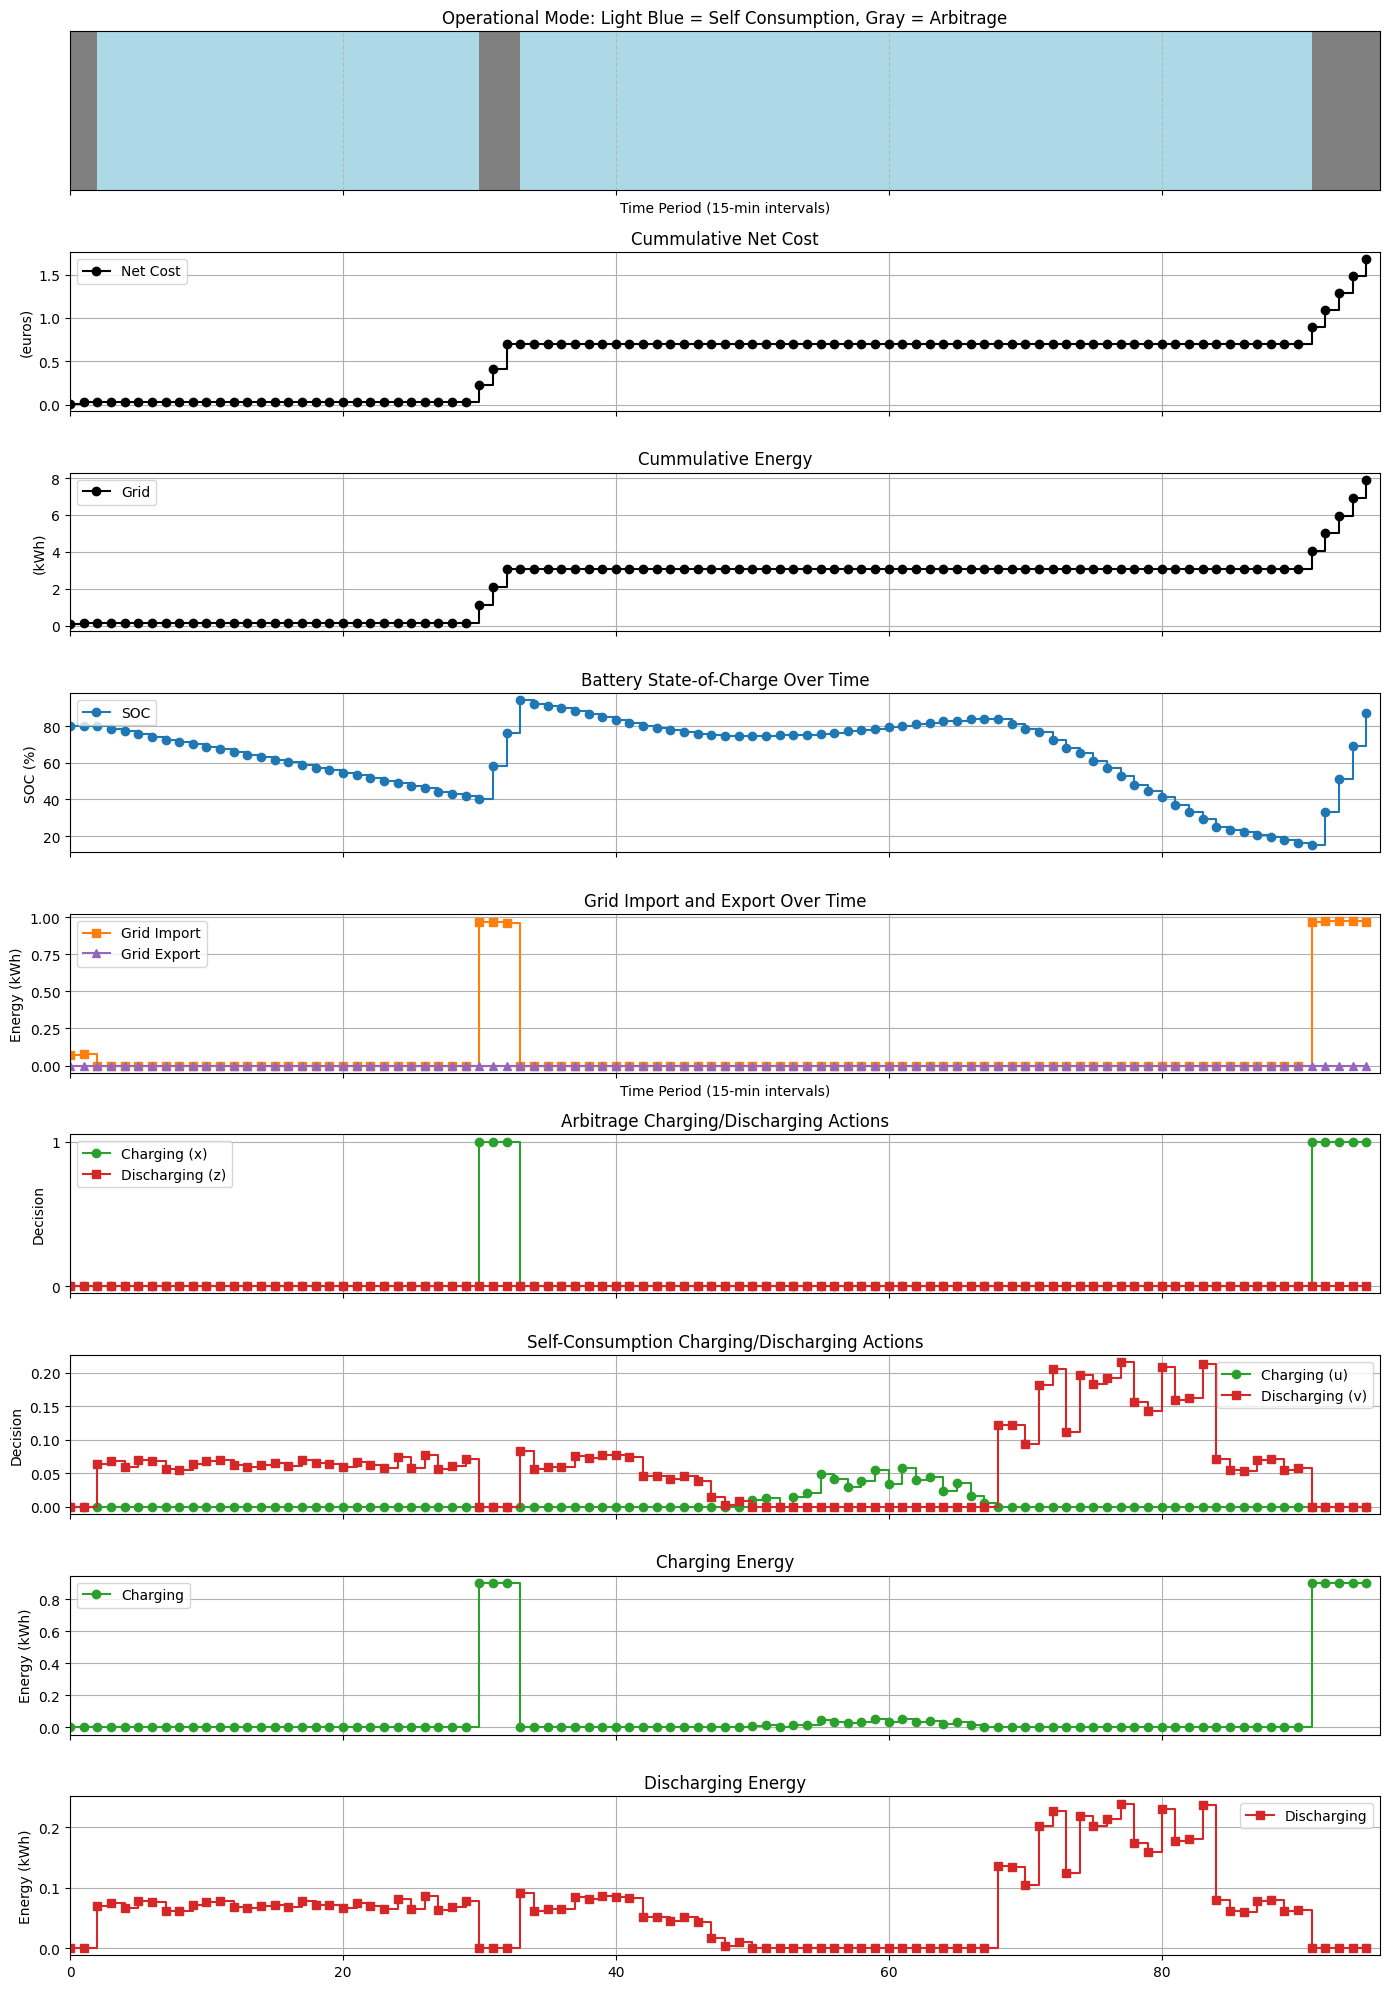

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming that the following variables are defined from the HiGHS solution:
# time_periods: a list of time period indices (e.g., range(T))
# h: your solved HiGHS model, where h.variableValue(var) returns the optimal value for a given variable.
# Also assume that the following solution arrays have been extracted from the HiGHS solution:
soc_solution = np.array([h.variableValue(soc[t]) for t in time_periods])
grid_in_solution = np.array([h.variableValue(grid_in[t]) for t in time_periods])
grid_out_solution = np.array([h.variableValue(grid_out[t]) for t in time_periods])
fob_solution = np.array([h.variableValue(grid_in[t])*price_consumption[t] - h.variableValue(grid_out[t])*price_injection[t] for t in time_periods])
mode_solution = np.array([h.variableValue(m[t]) for t in time_periods])
charge_solution = np.array([h.variableValue(charge[t]) for t in time_periods])
discharge_solution = np.array([h.variableValue(discharge[t]) for t in time_periods])

x_solution = np.array([h.variableValue(x[t]) for t in time_periods])
z_solution = np.array([h.variableValue(z[t]) for t in time_periods])
u_solution = np.array([h.variableValue(u[t]) for t in time_periods])
v_solution = np.array([h.variableValue(v[t]) for t in time_periods])

# ---------------------------
# Figure 1: EMS Results
# ---------------------------
fig1, axs1 = plt.subplots(9, 1, figsize=(14, 20), sharex=True)
i=-1

# Operational Mode
i+=1
for t in time_periods:
    # Determine color: light blue for self consumption (m[t] = 0), gray for arbitrage (m[t] = 1)
    color = 'lightblue' if mode_solution[t] < 0.5 else 'gray'
    axs1[i].broken_barh([(t, 1)], (0, 1), facecolors=color)

axs1[i].set_ylim(0, 1)
axs1[i].set_xlim(0, T)
axs1[i].set_xlabel("Time Period (15-min intervals)")
axs1[i].set_yticks([])
axs1[i].set_title("Operational Mode: Light Blue = Self Consumption, Gray = Arbitrage")
axs1[i].grid(True, axis='x', linestyle='--', alpha=0.7)

# Plot Cummulative cost
i+=1
axs1[i].step(time_periods, np.cumsum(fob_solution), where='post', marker='o', linestyle='-', color='black')
axs1[i].set_ylabel("(euros)")
axs1[i].set_title("Cummulative Net Cost")
axs1[i].grid(True)
axs1[i].legend(["Net Cost"])

# Plot Cummulative cost
i+=1
axs1[i].step(time_periods, np.cumsum(grid_in_solution), where='post', marker='o', linestyle='-', color='black')
axs1[i].set_ylabel("(kWh)")
axs1[i].set_title("Cummulative Energy")
axs1[i].grid(True)
axs1[i].legend(["Grid"])

# Plot Battery SOC
i+=1
axs1[i].step(time_periods, soc_solution, where='post', marker='o', linestyle='-', color='tab:blue')
axs1[i].set_ylabel("SOC (%)")
axs1[i].set_title("Battery State-of-Charge Over Time")
axs1[i].grid(True)
axs1[i].legend(["SOC"])

# Plot Grid Import and Export
# Contracted energy per period (P_contract * delta_t)
i+=1
max_energy_per_period = P_contract * delta_t
axs1[i].step(time_periods, grid_in_solution, where='post', marker='s', linestyle='-', label="Grid Import", color='tab:orange')
axs1[i].step(time_periods, grid_out_solution,where='post',  marker='^', linestyle='-', label="Grid Export", color='tab:purple')
if np.max(grid_out_solution) >=max_energy_per_period or np.max(grid_in_solution) >=max_energy_per_period:
    axs1[i].axhline(max_energy_per_period, color='tab:red', linestyle='--', linewidth=2,
               label=f"Contracted Limit ({max_energy_per_period:.2f} kWh)")

axs1[i].set_xlabel("Time Period (15-min intervals)")
axs1[i].set_ylabel("Energy (kWh)")
axs1[i].set_title("Grid Import and Export Over Time")
axs1[i].grid(True)
axs1[i].legend()


# Plot Charging (x) and Discharging (z) Decisions
i+=1
axs1[i].step(time_periods, x_solution, where='post', marker='o', linestyle='-', color='tab:green', label="Charging (x)")
axs1[i].step(time_periods, z_solution, where='post', marker='s', linestyle='-', color='tab:red', label="Discharging (z)")
axs1[i].set_ylabel("Decision")
axs1[i].set_title("Arbitrage Charging/Discharging Actions")
axs1[i].set_yticks([0, 1])
axs1[i].grid(True)
axs1[i].legend()

# Plot the self consumption charging and discharging energy
i+=1
axs1[i].step(time_periods, u_solution, where='post', marker='o', linestyle='-', color='tab:green', label="Charging (u)")
axs1[i].step(time_periods, v_solution, where='post', marker='s', linestyle='-', color='tab:red', label="Discharging (v)")
axs1[i].set_ylabel("Decision")
axs1[i].set_title("Self-Consumption Charging/Discharging Actions")
axs1[i].legend()
axs1[i].grid(True)

# Plot the self consumption charging energy
i+=1
axs1[i].step(time_periods, charge_solution, where='post', marker='o', linestyle='-', color='tab:green', label="Charging")
axs1[i].set_ylabel("Energy (kWh)")
axs1[i].set_title("Charging Energy")
axs1[i].legend()
axs1[i].grid(True)

# Plot the self consumption discharging energy
i+=1
axs1[i].step(time_periods, discharge_solution, where='post', marker='s', linestyle='-', color='tab:red', label="Discharging")
axs1[i].set_ylabel("Energy (kWh)")
axs1[i].set_title("Discharging Energy")
axs1[i].legend()
axs1[i].grid(True)

plt.tight_layout()
plt.show()

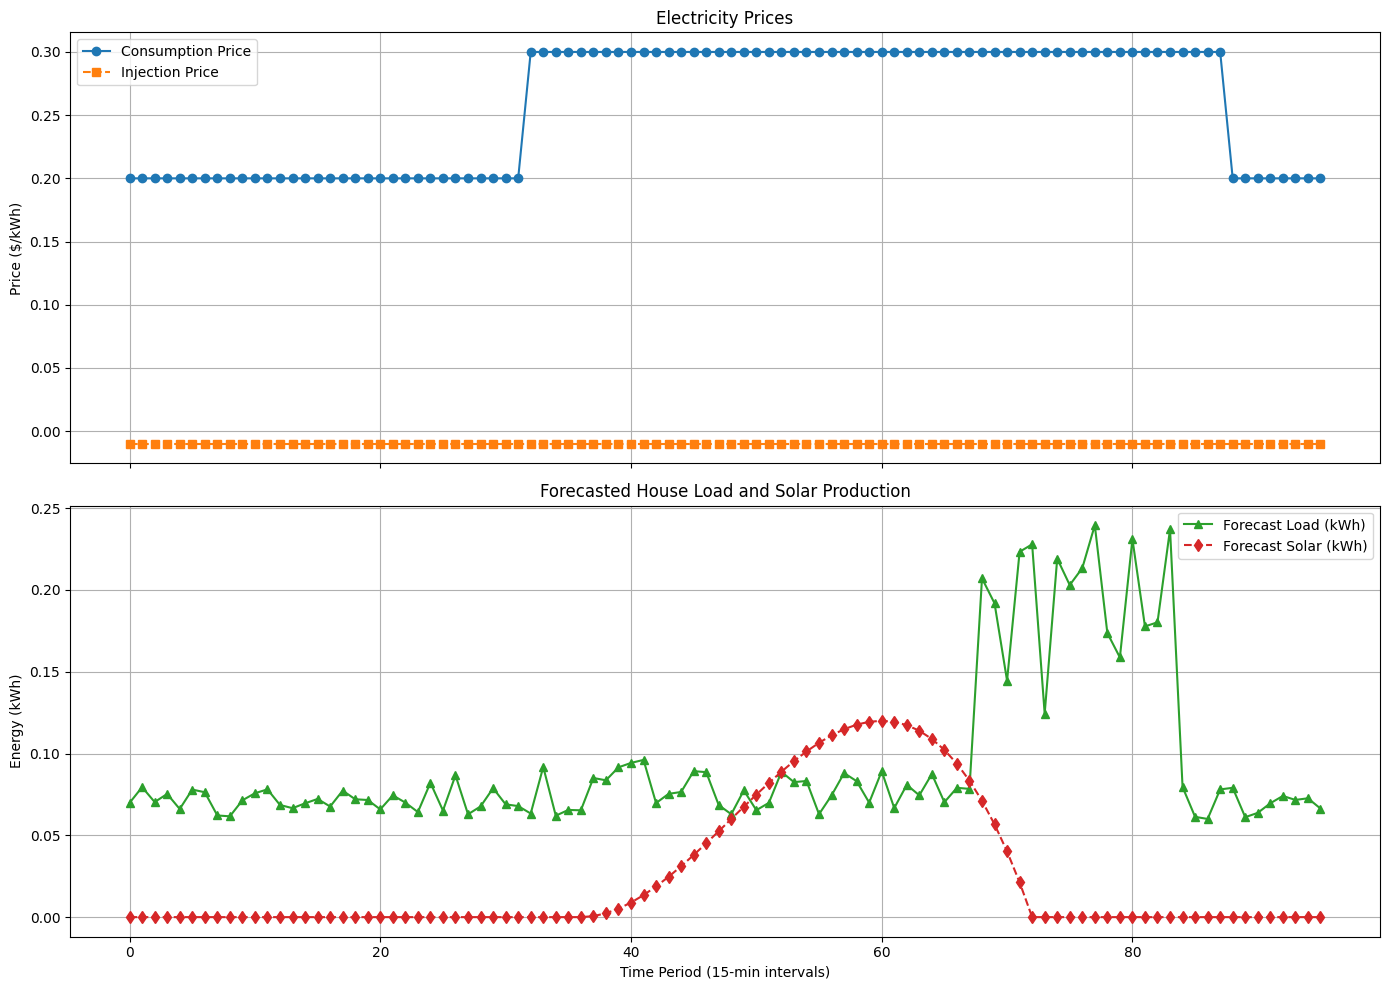

In [7]:
# ---------------------------
# Figure 2: Parameter Graphs
# ---------------------------
fig2, axs2 = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Plot Electricity Prices (Consumption and Injection)
axs2[0].plot(time_periods, price_consumption, marker='o', linestyle='-', color='tab:blue', label='Consumption Price')
axs2[0].plot(time_periods, price_injection, marker='s', linestyle='--', color='tab:orange', label='Injection Price')
axs2[0].set_ylabel("Price ($/kWh)")
axs2[0].set_title("Electricity Prices")
axs2[0].legend()
axs2[0].grid(True)

# Plot Forecasted House Load and Solar Production
axs2[1].plot(time_periods, forecast_load, marker='^', linestyle='-', color='tab:green', label='Forecast Load (kWh)')
axs2[1].plot(time_periods, forecast_solar, marker='d', linestyle='--', color='tab:red', label='Forecast Solar (kWh)')
axs2[1].set_xlabel("Time Period (15-min intervals)")
axs2[1].set_ylabel("Energy (kWh)")
axs2[1].set_title("Forecasted House Load and Solar Production")
axs2[1].legend()
axs2[1].grid(True)

plt.tight_layout()
plt.show()